In [1]:
import math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from optical_communication_system.components import *
from optical_communication_system.components.utils import normalize_signal, psk_constellation, symbol_mapping_to_gray
from optical_communication_system.plot import *

2024-09-27 05:05:08.077663: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-09-27 05:05:08.115260: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-09-27 05:05:08.115289: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-09-27 05:05:08.116533: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-09-27 05:05:08.122614: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-09-27 05:05:08.123385: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [2]:
Component.trace_debug_enabled_by_default = True

data_rate = 1e9
sampling_rate = data_rate * 10
central_frequency = 193.414e12 # Hz

input_power = 2e-3 # Watts

lpf = BandPassFilter(min_frequency=0.0, max_frequency=1 * data_rate, name="lpf")

qam4_mapping = symbol_mapping_to_gray([
    [-1.0, -1.0], [-1.0, 1.0],
    [ 1.0, -1.0], [ 1.0, 1.0]
])

qam16_mapping = symbol_mapping_to_gray([
    [-1.0,  1.0], [-1.0,  0.5], [-1.0, -0.5], [-1.0, -1.0],
    [-0.5, -1.0], [-0.5, -0.5], [-0.5,  0.5], [-0.5,  1.0],
    [ 0.5,  1.0], [ 0.5,  0.5], [ 0.5, -0.5], [ 0.5, -1.0],
    [ 1.0, -1.0], [ 1.0, -0.5], [ 1.0,  0.5], [ 1.0,  1.0]
])

psk4_mapping = symbol_mapping_to_gray(psk_constellation(2))
psk16_mapping = symbol_mapping_to_gray(psk_constellation(4))
psk256_mapping = symbol_mapping_to_gray(psk_constellation(8))

bits_per_symbol, symbol_mapping = 4, qam16_mapping

snr = 30.0

channel = OpticalFiber(
    attenuation=0.22,
    length=40.0,
    chromatic_dispersion=17.0,
    eff_non_linear_coeff=1.76,
    central_frequency=central_frequency,
    step_count=1000,
    name="channel"
)

input_laser = Composition(components=[
    Laser(power=input_power, name="laser"),
    OpticalAWGN(power=input_power / 10 ** (snr * 0.1))
])

link_training_system = Composition(components=[
    PAMEncoder(
        sampling_rate=sampling_rate,
        data_rate=data_rate,
        symbol_encoder=PAMSymbolEncoder(
            bits_per_symbol=1,
            mapping=[0.0, 1.0],
            adjust_for_mzm=True
        )
    ),
    lpf,
    MachZehnderModulator(carrier_source=input_laser),
    channel,
    Composition(components=[Photodiode(), lpf], name="lts_pd"),
    Downsample(sampling_rate=data_rate, time_offset=0.5 / data_rate),
    MeanAmplitude()
], name="link_training_system")

transmitter = Composition(components=[
    IQEncoder(
        sampling_rate=sampling_rate,
        data_rate=data_rate,
        symbol_encoder=IQSymbolEncoder(
            bits_per_symbol=bits_per_symbol,
            mapping=symbol_mapping,
            adjust_for_mzm=True,
            name="iq_symbol_encoder"
        )
    ),  # (ElectricalSignal, ElectricalSignal)
    MapComponent(component=lpf, name="encoder_output"),  # (ElectricalSignal, ElectricalSignal)
    IQModulator(carrier_source=input_laser, name="modulator"),  # OpticalSignal
], name="transmitter")

receiver = Composition(components=[
    IQReceiver(
        photodiode=Composition(components=[Photodiode(), lpf]),
        local_oscillator=Laser(power=2e-3),
        name="receiver_output"
    ),  # (ElectricalSignal, ElectricalSignal)
    IQDecoder(
        data_rate=data_rate,
        symbol_decoder=IQSymbolDecoder(
            bits_per_symbol=bits_per_symbol,
            mapping=qam16_mapping,
            name="iq_symbol_decoder"
        ),
        name="decoder_output"
    )  # tf.TensorSpec(shape=[None], dtype=tf.int32)
])

system = Composition(components=[transmitter, channel, receiver])

rng = tf.random.Generator.from_non_deterministic_state(alg="philox")
ber_tester = BERTester([system])

In [10]:
input_signal = tf.constant([1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1], dtype=tf.int32)
input_signal = rng.uniform((512,), 0, 2, dtype=tf.int32)

test_pattern = tf.constant([1, 0, 1, 0, 1, 0, 1, 0], dtype=tf.int32)

system_params = dict(
    channel__step_count=tf.constant(10000),
    channel__length=tf.constant(5.0),
    channel__eff_non_linear_coeff=tf.constant(1.76 * 10e4),
    iq_symbol_encoder__mapping=tf.constant(qam16_mapping),
    iq_symbol_decoder__mapping=tf.constant(qam16_mapping),
    iq_symbol_encoder__bits_per_symbol=tf.constant(4),
    iq_symbol_decoder__bits_per_symbol=tf.constant(4)
)

symbol_scale = 2 ** 0.5 * link_training_system.trace(test_pattern, **system_params)
system_params["decoder_output__symbol_scale"] = symbol_scale

system.trace(input_signal, **system_params)

Calling Composition(name='link_training_system') with args tf.Tensor(shape=[8], dtype=tf.int32)
|---Calling PAMEncoder(name='pam_encoder') with args tf.Tensor(shape=[8], dtype=tf.int32)
|---|---Return ElectricalSignal
|---Calling BandPassFilter(name='lpf') with args ElectricalSignal
|---|---Return ElectricalSignal
|---Calling MachZehnderModulator(name='mach_zehnder_modulator') with args ElectricalSignal
|---|---Return OpticalSignal
|---Calling OpticalFiber(name='channel') with args OpticalSignal
|---|---Return OpticalSignal
|---Calling Composition(name='lts_pd') with args OpticalSignal
|---|---Calling Photodiode(name='photodiode') with args OpticalSignal
|---|---|---Return ElectricalSignal
|---|---Calling BandPassFilter(name='lpf') with args ElectricalSignal
|---|---|---Return ElectricalSignal
|---|---Return ElectricalSignal
|---Calling Downsample(name='downsample') with args ElectricalSignal
|---|---Return ElectricalSignal
|---Calling MeanAmplitude(name='mean_amplitude') with args Ele

<tf.Tensor: shape=(512,), dtype=int32, numpy=
array([0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1,
       0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0,
       0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1,
       0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1,
       1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0,
       1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0,
     

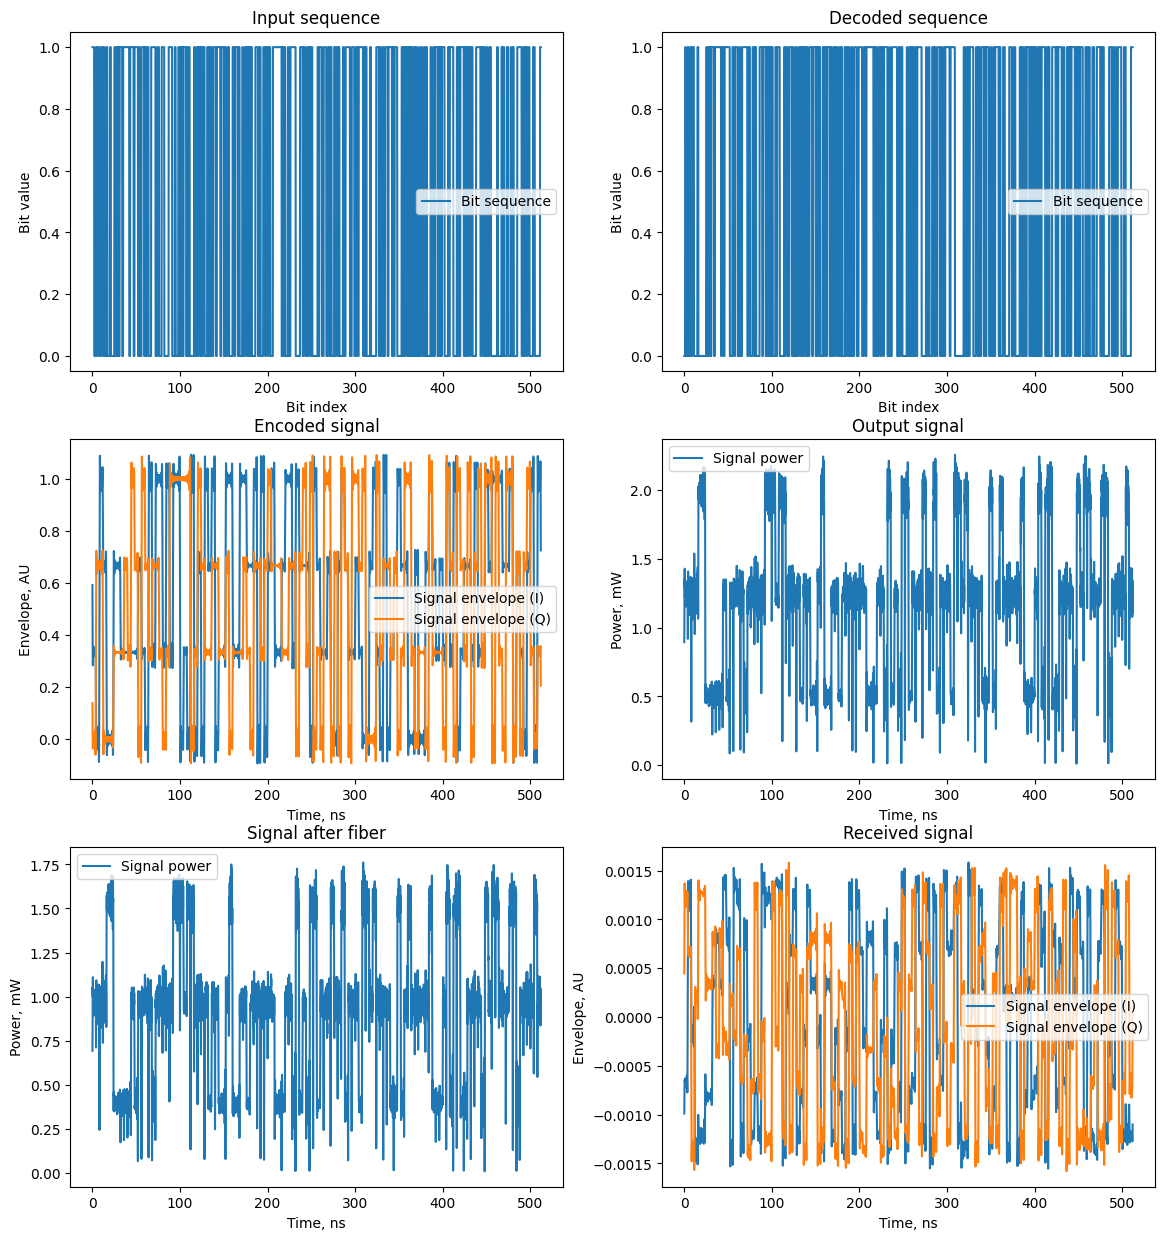

In [11]:
fig, ((input_ax, decoded_ax), (encoded_ax, output_ax), (fiber_ax, received_ax)) = plt.subplots(3, 2)  # type: ignore
fig.set_size_inches(14, 15)

axes = [
    (input_ax, "Input sequence"),
    (encoded_ax, "Encoded signal"),
    (output_ax, "Output signal"),
    (fiber_ax, "Signal after fiber"),
    (received_ax, "Received signal"),
    (decoded_ax, "Decoded sequence")
]

plot_bitseq(input_signal, input_ax)
plot_envelope(system.find_child("encoder_output").output, encoded_ax)
plot_power(system.find_child("modulator").output, output_ax)
plot_power(system.find_child("channel").output, fiber_ax)

plot_envelope(system.find_child("receiver_output").output, received_ax)

plot_bitseq(system.output, decoded_ax)

for ax, title in axes:
    ax.set_title(title)
    ax.legend()

(-1.3317588210105895,
 1.376298260688782,
 -1.3533394515514374,
 1.354717630147934)

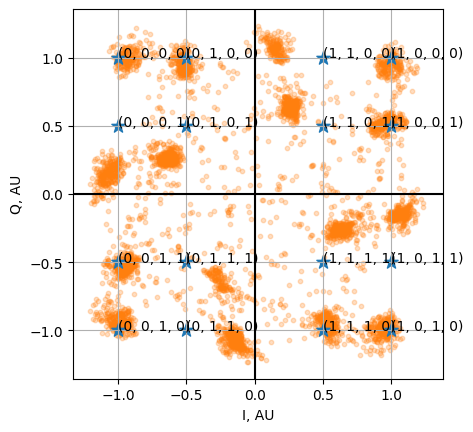

In [16]:
plt.axhline(0.0, color="black")
plt.axvline(0.0, color="black")
plt.grid()
plot_iq_constellation(system.find_child("receiver_output").output, s=10, iq_units=(1 / symbol_scale, "AU"), alpha=0.25, color="tab:orange")
plot_iq_constellation(tf.constant(symbol_mapping), s=100, marker="*", color="tab:blue")

annotate_constellation = True

if annotate_constellation:
    for i, symbol in enumerate(symbol_mapping):
        bit_string = ', '.join(
            tuple(
                bin(i)[2:].zfill(
                    int(bits_per_symbol)
                )
            )
        )
    
        plt.annotate(f"({bit_string})", (symbol[0], symbol[1]))

plt.axis("square")

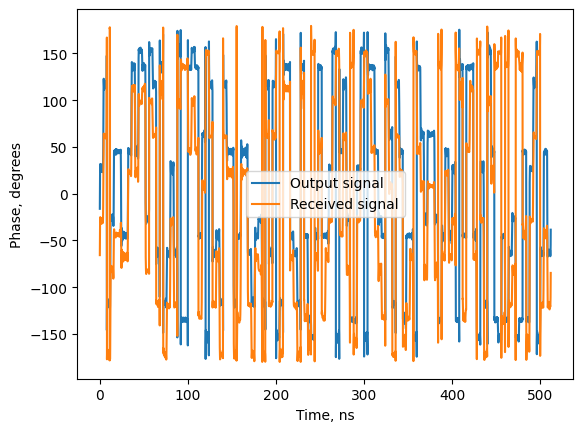

In [17]:
plot_phase(system.find_child("modulator").output, label="Output signal")
plot_phase(system.find_child("receiver_output").output, label="Received signal")
plt.legend()

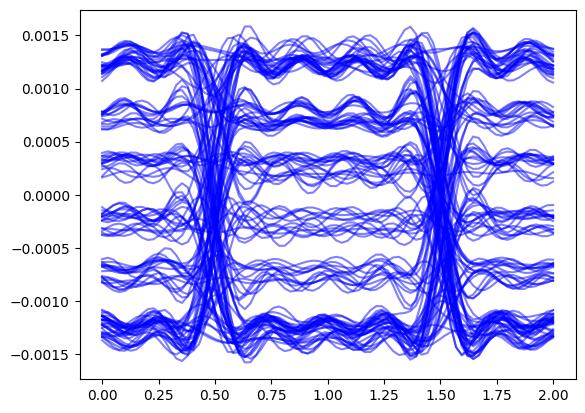

In [18]:
for signal in system.find_child("receiver_output").output:
    plot_eye_diagram(signal, color="blue", alpha=0.5)

In [19]:
%time ber_tester(tf.constant(128), **system_params)

CPU times: user 40.2 s, sys: 1.27 s, total: 41.5 s
Wall time: 13.2 s


<tf.Tensor: shape=(1,), dtype=float32, numpy=array([0.25], dtype=float32)>